--- Temperaturstatistikk Ås (2025) ---
 Mean (°C)  Median (°C)  Min (°C)  Max (°C)
       7.9          8.4     -15.5      23.7


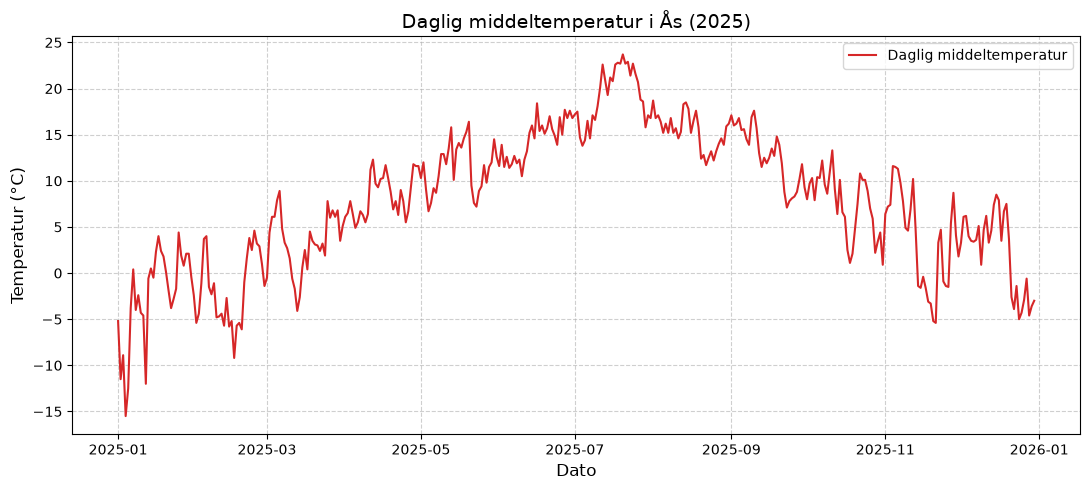

In [8]:
import matplotlib.pyplot as plt
import pandas as pd
import requests

# 1. Les inn din skjulte Client-ID fra tekstfilen
with open('../client_id.txt', 'r') as f:
    client_id = f.read().strip()

# 2. Definer endepunkt og parametere spesifisert i oppgaven
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
    'sources': 'SN17850',                    # Værstasjon for Ås
    'elements': 'mean(air_temperature P1D)', # Daglig middeltemperatur
    'referencetime': '2025-01-01/2025-12-31' # Hele året 2025
}

# 3. Hent data fra Frost API
r = requests.get(endpoint, parameters, auth=(client_id, ''))
json_data = r.json()

# Sjekk at forespørselen gikk bra
if r.status_code == 200:
    # 4. Pakk ut observasjonsdataene til en DataFrame
    data_list = []
    for item in json_data['data']:
        data_list.append({
            'referenceTime': item['referenceTime'],
            'temperature': item['observations'][0]['value']
        })

    df_2025 = pd.DataFrame(data_list)
    df_2025['referenceTime'] = pd.to_datetime(df_2025['referenceTime'])

    # 5. Lag sammendragstabell med mean, median, min og max
    summary_table = pd.DataFrame({
        'Mean (°C)': [df_2025['temperature'].mean()],
        'Median (°C)': [df_2025['temperature'].median()],
        'Min (°C)': [df_2025['temperature'].min()],
        'Max (°C)': [df_2025['temperature'].max()]
    })

    # Skriv ut tabellen med print()
    print("--- Temperaturstatistikk Ås (2025) ---")
    print(summary_table.round(2).to_string(index=False))

    # 6. Lag plott for daglig middeltemperatur (tid på x-aksen, temp på y-aksen)
    plt.figure(figsize=(11, 5))
    plt.plot(df_2025['referenceTime'], df_2025['temperature'], color='tab:red', linewidth=1.5, label='Daglig middeltemperatur')
    
    plt.title('Daglig middeltemperatur i Ås (2025)', fontsize=14)
    plt.xlabel('Dato', fontsize=12)
    plt.ylabel('Temperatur (°C)', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()
    plt.tight_layout()
    plt.show()

else:
    print(f"Feil ved henting av data. Statuskode: {r.status_code}")
    print(json_data.get('error', {}).get('message', 'Ukjent feil'))

--- Nedbørstatistikk Ås (2025) ---
 Totalt (mm)  Snitt per dag (mm)  Maks på én dag (mm)
       942.2                 2.6                 36.1


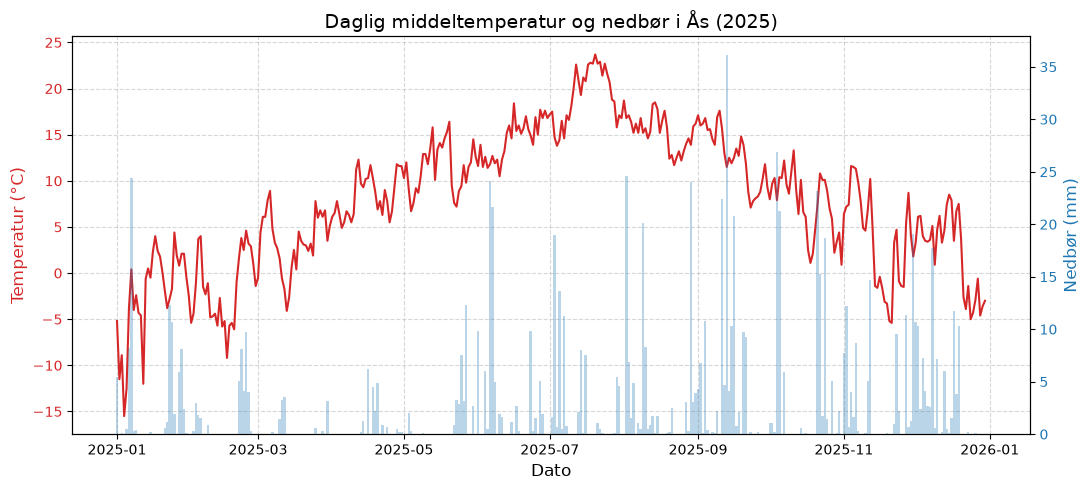

In [ ]:
# --- OPPGAVE 2 ---

# 1. Hent kun nedbørsdata for 2025
parameters_precip = {
    'sources': 'SN17850',
    'elements': 'sum(precipitation_amount P1D)',
    'referencetime': '2025-01-01/2025-12-31'
}

r_precip = requests.get(endpoint, parameters_precip, auth=(client_id, ''))

if r_precip.status_code == 200:
    # 2. Legg nedbørsverdiene rett inn i den eksisterende df_2025-tabellen din
    precip_data = [item['observations'][0]['value'] for item in r_precip.json()['data']]
    df_2025['precipitation'] = precip_data

    # 3. Sammendragstabell for nedbør
    precip_summary = pd.DataFrame({
        'Totalt (mm)': [df_2025['precipitation'].sum()],
        'Snitt per dag (mm)': [df_2025['precipitation'].mean()],
        'Maks på én dag (mm)': [df_2025['precipitation'].max()]
    })

    print("--- Nedbørstatistikk Ås (2025) ---")
    print(precip_summary.round(1).to_string(index=False))

    # 4. Kombinert plott med to Y-akser (Temperatur + Nedbør)
    fig, ax1 = plt.subplots(figsize=(11, 5))

    # Venstre y-akse: Temperatur (Rød linje fra Oppgave 1)
    ax1.set_xlabel('Dato', fontsize=12)
    ax1.set_ylabel('Temperatur (°C)', color='tab:red', fontsize=12)
    ax1.plot(df_2025['referenceTime'], df_2025['temperature'], color='tab:red', linewidth=1.5, label='Temperatur')
    ax1.tick_params(axis='y', labelcolor='tab:red')

    # Høyre y-akse: Nedbør (Blå søyler)
    ax2 = ax1.twinx()
    ax2.set_ylabel('Nedbør (mm)', color='tab:blue', fontsize=12)
    ax2.bar(df_2025['referenceTime'], df_2025['precipitation'], color='tab:blue', alpha=0.3, width=1.0, label='Nedbør')
    ax2.tick_params(axis='y', labelcolor='tab:blue')

    plt.title('Daglig middeltemperatur og nedbør i Ås (2025)', fontsize=14)
    ax1.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

else:
    print("Feil ved henting av nedbør data.")